# Boston Prediction — Part 1: Exploratory Data Analysis (EDA)

**Goal of the project:** predict a house price


**In this notebook:** 
1. data overview
2. cleaning
3. univariate analysis
4. bivariate analysis (against churn)
5. correlations
6. outliers
7. key findings.

## 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the data

In [4]:
df = pd.read_csv("boston_data.csv.")
df.head()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,5,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9


### Column Description
1. RowNumber – Unique row number or record identifier. No predictive value.
2. CustomerId – Unique ID assigned to each customer. Generally not useful for prediction.
3. Surname – Customer's surname or last name. Generally not useful for prediction.
4. CreditScore – Customer's credit score, indicating their creditworthiness.
5. Geography – Customer's country, such as France, Spain, or Germany.
6. Gender – Customer's gender, Male or Female.
7. Age – Customer's age in years.
8. Tenure – Number of years the customer has been with the bank.
9. Balance – Amount of money maintained in the customer's bank account.
10. NumOfProducts – Number of banking products or services used by the customer.
11. HasCrCard – Indicates whether the customer has a credit card. 1 means Yes, and 0 means No.
12. IsActiveMember – Indicates whether the customer is an active bank member. 1 means Active, and 0 means Inactive.
13. EstimatedSalary – Estimated annual salary of the customer.
14. Exited – Target variable indicating customer churn. 1 means the customer left the bank, and 0 means the customer stayed with the bank.

## 3. Basic data inspection

In [5]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (333, 12)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ID       333 non-null    int64  
 1   indus    333 non-null    float64
 2   chas     333 non-null    int64  
 3   nox      333 non-null    float64
 4   rm       333 non-null    float64
 5   age      333 non-null    float64
 6   dis      333 non-null    float64
 7   rad      333 non-null    int64  
 8   tax      333 non-null    int64  
 9   ptratio  333 non-null    float64
 10  lstat    333 non-null    float64
 11  medv     333 non-null    float64
dtypes: float64(8), int64(4)
memory usage: 31.3 KB


In [7]:
df.describe()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000
mean,250.951952,11.293483,0.060060,0.557144,6.265619,68.226426,3.709934,9.633634,409.279279,18.448048,12.515435,22.768769
std,147.859438,6.998123,0.237956,0.114955,0.703952,28.133344,1.981123,8.742174,170.841988,2.151821,7.067781,9.173468
min,1.000000,0.740000,0.000000,0.385000,3.561000,6.000000,1.129600,1.000000,188.000000,12.600000,1.730000,5.000000
25%,123.000000,5.130000,0.000000,0.453000,5.884000,45.400000,2.122400,4.000000,279.000000,17.400000,7.180000,17.400000
50%,244.000000,9.900000,0.000000,0.538000,6.202000,76.700000,3.092300,5.000000,330.000000,19.000000,10.970000,21.600000
75%,377.000000,18.100000,0.000000,0.631000,6.595000,93.800000,5.116700,24.000000,666.000000,20.200000,16.420000,25.000000
max,506.000000,27.740000,1.000000,0.871000,8.725000,100.000000,10.710300,24.000000,711.000000,21.200000,37.970000,50.000000


In [8]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
ID         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
lstat      0
medv       0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Unique values per column:")
print(df.nunique())

Unique values per column:
ID         333
indus       68
chas         2
nox         77
rm         308
age        260
dis        295
rad          9
tax         59
ptratio     42
lstat      310
medv       192
dtype: int64


##### Observations
- No missing values and no duplicate rows, so no imputation is needed.

## 4. Univariate analysis

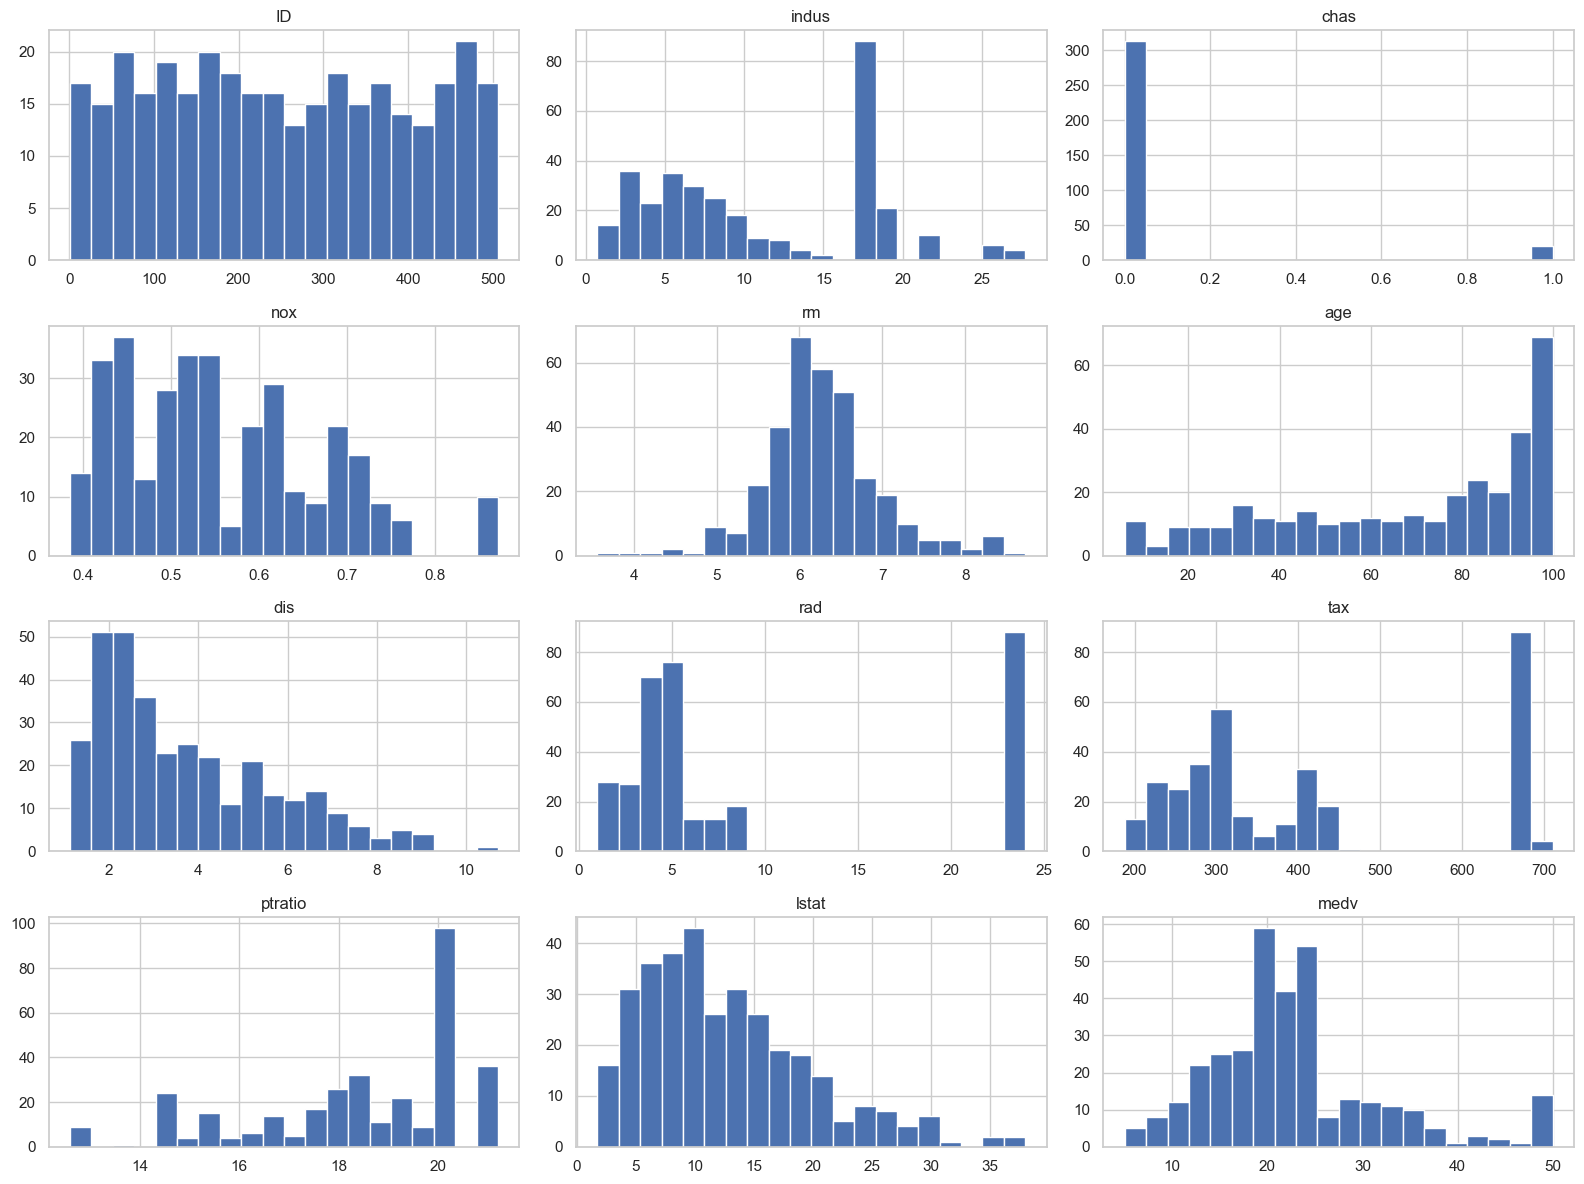

In [12]:
# Plots all numerical columns
df.hist(figsize=(16, 12), bins=20, color="#4c72b0")
plt.tight_layout()
plt.show()

In [13]:
print("Skewness of numerical columns:")
print(df.skew().round(2))

Skewness of numerical columns:
ID         0.06
indus      0.29
chas       3.72
nox        0.71
rm         0.28
age       -0.60
dis        0.94
rad        0.98
tax        0.63
ptratio   -0.79
lstat      0.98
medv       1.12
dtype: float64


##### Observations – Boston Housing Dataset
- INDUS shows variation in the proportion of non-retail business acres across towns.
- CHAS is binary: most observations are 0, meaning they do not border the Charles River.
- NOX shows variation in nitrogen oxide concentration across locations.
- RM is approximately bell-shaped: most houses have around 5–7 rooms per dwelling.
- AGE has many high values, indicating that a large proportion of owner-occupied homes were built before 1940.
- DIS is distributed across different distances from employment centers.
- RAD contains discrete integer values and is concentrated at certain accessibility levels.
- TAX varies considerably across towns, with concentrations at particular tax rates.
- PTRATIO shows differences in the pupil–teacher ratio across towns.
- B has a skewed distribution and reflects a historically defined census variable.
- LSTAT is right-skewed: many observations have relatively low values, with some much higher values.
- MEDV (target) shows the distribution of median owner-occupied home values. It has a noticeable upper-end pile-up at 50, indicating a cap in the original dataset.